# 05 Test set and final refit

The model, its predictor subset and the threshold are frozen from notebooks 03 and 04 (`results/selected_model.json`, `results/operating_point.json`). This notebook loads the test set for the first and only time (793 wines, one row per wine), scores the frozen model on it, reports the test results side by side with the CV estimates, and then refits the same specification on all 3,961 wines. Nothing is changed after the test results are seen.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

from wine_utils import (load_train, load_test, load_split, load_all, transform, build_selected,
                        expected_cost, ALL_FEATURES, C_FN_BASE)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

spec = json.load(open('results/selected_model.json'))
op = json.load(open('results/operating_point.json'))
assert op['model'] == spec['name']
t = op['threshold']
X_train, y_train = load_train()
print(f"Frozen: {spec['name']} on {spec['n_predictors']} predictors {spec['predictors']}, threshold {t:g}")

Frozen: Logistic on 6 predictors ['fixed acidity', 'log residual sugar', 'free sulfur dioxide', 'density', 'pH', 'log sulphates'], threshold 0.2


## Fit the frozen specification on the full training set

In [2]:
model = build_selected(spec).fit(X_train, y_train)
assert model.named_steps['model'].n_features_in_ == len(spec['predictors'])
assert list(model[:-1].get_feature_names_out()) == spec['predictors']
print(spec['name'], 'fitted on', len(X_train), 'training wines')
model

Logistic fitted on 3168 training wines


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','log volatile acidity','citric acid',...,'pH', 'log sulphates','alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('keep', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to sett

## Score the test set, once

Test wines: 793 | share good: 0.208 | no duplicates, no overlap with training


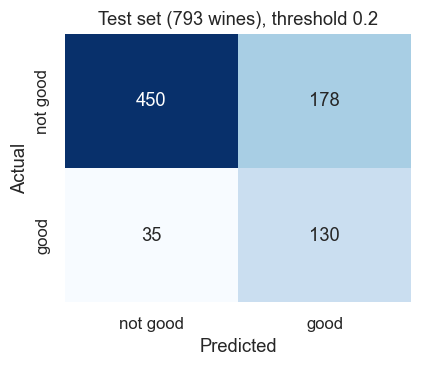

In [3]:
X_test, y_test = load_test()
train_df, test_df = load_split('train'), load_split('test')
assert len(X_test) == 793 and not test_df.duplicated().any()
assert len(train_df.merge(test_df, how='inner')) == 0, 'a wine appears in both train and test'
print('Test wines:', len(y_test), '| share good:', round(y_test.mean(), 3),
      '| no duplicates, no overlap with training')

prob = model.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, prob >= t).ravel()
test = {'PR-AUC': average_precision_score(y_test, prob),
        'ROC-AUC': roc_auc_score(y_test, prob),
        f'Sensitivity @{t:g}': tp / (tp + fn),
        f'Specificity @{t:g}': tn / (tn + fp),
        f'Cost per wine @{t:g}': expected_cost(y_test, prob, t, C_FN_BASE)}

fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
            xticklabels=['not good', 'good'], yticklabels=['not good', 'good'])
ax.set(xlabel='Predicted', ylabel='Actual', title=f'Test set ({len(y_test)} wines), threshold {t:g}')
plt.tight_layout()
plt.show()

### CV estimates and test results side by side

CV values are mean ± SE over the 10 folds of the nested CV in notebook 03 (out-of-fold predictions of the selected model; sensitivity, specificity and cost at the chosen threshold are computed per fold from the same predictions).

In [4]:
oof = pd.read_csv('results/oof_probabilities.csv', index_col=0)
cv_folds = []
for f, d in oof.groupby('fold'):
    p, yy = d[spec['name']].to_numpy(), d['y'].to_numpy()
    c_tn, c_fp, c_fn, c_tp = confusion_matrix(yy, p >= t, labels=[0, 1]).ravel()
    cv_folds.append({'PR-AUC': average_precision_score(yy, p), 'ROC-AUC': roc_auc_score(yy, p),
                     f'Sensitivity @{t:g}': c_tp / (c_tp + c_fn), f'Specificity @{t:g}': c_tn / (c_tn + c_fp),
                     f'Cost per wine @{t:g}': expected_cost(yy, p, t, C_FN_BASE)})
cv_folds = pd.DataFrame(cv_folds)
assert np.isclose(cv_folds['PR-AUC'].mean(), spec['cv_pr_auc_mean'])

comparison = pd.DataFrame({
    'CV mean': cv_folds.mean(),
    'CV SE': cv_folds.std() / np.sqrt(len(cv_folds)),
    'Test': pd.Series(test),
})
comparison['|Test - CV|'] = (comparison['Test'] - comparison['CV mean']).abs()
comparison.to_csv('results/test_vs_cv.csv')
comparison.round(3)

,CV mean,CV SE,Test,|Test - CV|
PR-AUC,0.535,0.018,0.544,0.010
ROC-AUC,0.802,0.011,0.820,0.018
Sensitivity @0.2,0.779,0.017,0.788,0.009
Specificity @0.2,0.714,0.009,0.717,0.003
Cost per wine @0.2,0.365,0.011,0.357,0.008


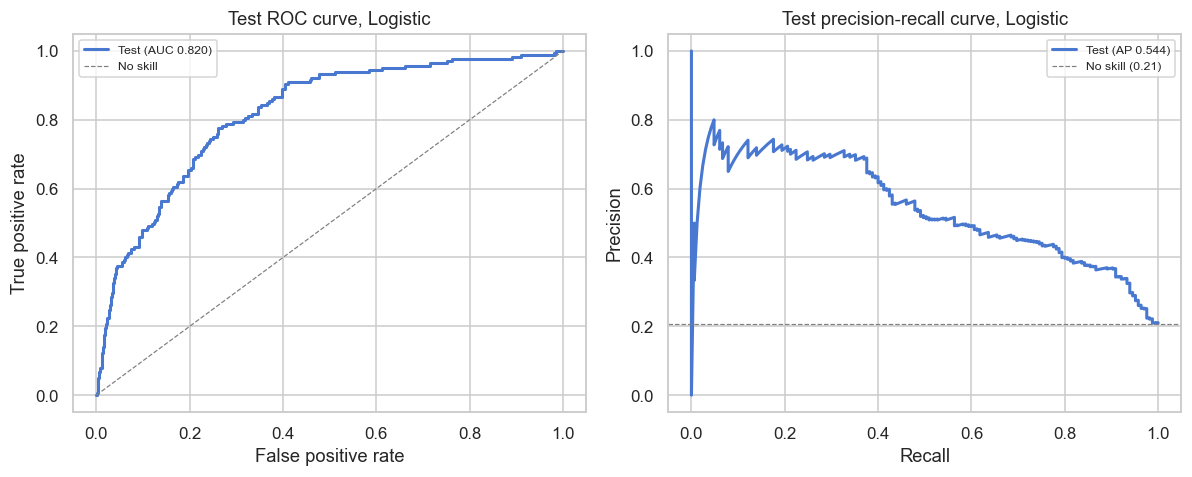

In [5]:
fpr, tpr, _ = roc_curve(y_test, prob)
prec, rec, _ = precision_recall_curve(y_test, prob)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, lw=2, label=f"Test (AUC {test['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color='grey', ls='--', lw=0.8, label='No skill')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title=f'Test ROC curve, {spec["name"]}')
axes[1].plot(rec, prec, lw=2, label=f"Test (AP {test['PR-AUC']:.3f})")
axes[1].axhline(y_test.mean(), color='grey', ls='--', lw=0.8, label=f'No skill ({y_test.mean():.2f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title=f'Test precision-recall curve, {spec["name"]}')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Refit the same specification on all data (3,961 wines)

Only the parameters are re-estimated. The selected predictor subset, transformations, model family and threshold stay frozen, and the performance figures to report remain the test results above. Predictors are standardised over the full data, so effects are per one-SD increase.

- **Logistic:** sklearn gives no standard errors, so the same unpenalised model is refitted in `statsmodels`. Each row is a different wine, so the usual model-based SEs are used. We report odds ratios per 1 SD.
- **LDA:** standardised discriminant coefficients (the weight of each predictor in the linear discriminant) and the standardised difference in class means.
- **Gaussian NB:** the standardised difference in class means for each predictor, which drives its per-feature likelihood ratio.

In [6]:
df_all = load_all()
assert len(df_all) == 3961
X_all = transform(df_all[ALL_FEATURES])
y_all = (df_all['quality'] >= 7).astype(int)

final_model = build_selected(spec).fit(X_all, y_all)   # the deployable model; selects spec['predictors']
Z_all = X_all[spec['predictors']]
Z_all = (Z_all - Z_all.mean()) / Z_all.std()

if spec['name'] == 'Logistic':
    final = sm.Logit(y_all, sm.add_constant(Z_all)).fit(disp=0)
    print(final.summary())
    ci = final.conf_int()
    effects = pd.DataFrame({
        'coef (log-odds per SD)': final.params,
        'odds ratio per SD': np.exp(final.params),
        'OR 95% CI low': np.exp(ci[0]),
        'OR 95% CI high': np.exp(ci[1]),
        'p-value': final.pvalues,
    }).drop('const').sort_values('odds ratio per SD', ascending=False)
else:
    mean_diff = Z_all[y_all == 1].mean() - Z_all[y_all == 0].mean()
    effects = pd.DataFrame({'class mean difference (good - not good, SDs)': mean_diff})
    if spec['name'] == 'LDA':
        lda = final_model.named_steps['model']
        effects['standardised discriminant coefficient'] = lda.scalings_[:, 0]
    effects = effects.sort_values(effects.columns[-1], key=np.abs, ascending=False)
effects.to_csv('results/refit_effects.csv')
effects.round(3)

                           Logit Regression Results                           
Dep. Variable:                quality   No. Observations:                 3961
Model:                          Logit   Df Residuals:                     3954
Method:                           MLE   Df Model:                            6
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.2047
Time:                        00:12:56   Log-Likelihood:                -1611.9
converged:                       True   LL-Null:                       -2026.7
Covariance Type:            nonrobust   LLR p-value:                5.900e-176
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -1.7757      0.054    -32.756      0.000      -1.882      -1.669
fixed acidity           0.5460      0.059      9.215      0.000       0.430       0.662
log residual sug

,coef (log-odds per SD),odds ratio per SD,OR 95% CI low,OR 95% CI high,p-value
log residual sugar,1.138,3.120,2.690,3.619,0.0
pH,0.640,1.897,1.702,2.113,0.0
fixed acidity,0.546,1.726,1.537,1.939,0.0
free sulfur dioxide,0.217,1.243,1.130,1.366,0.0
log sulphates,0.210,1.234,1.134,1.343,0.0
density,-2.123,0.120,0.100,0.143,0.0


## Limitations

- **Binarised outcome.** Quality is cut at 7, so the ordering within each class (a 3 vs a 6, a 7 vs a 9) is lost, and wines just either side of the cut are treated as fully different.
- **Noisy labels.** Each quality score is the median of at least three expert ratings, so some labels near the cut-off are effectively uncertain, which caps achievable accuracy.
- **One region and vintage period.** The data are Vinho Verde wines from a 2009 study (Cortez et al.). Results may not transfer to other regions, styles or later vintages.
- **Missing drivers.** There is no price, grape variety, brand or cost information, so the cost ratio $c_{FN}/c_{FP}$ is assumed, not measured (see the sensitivity analysis in notebook 04).
- **White wine only.** No conclusion is drawn about red wine.
- **Simplicity has a price.** Each classifier uses the simplest predictor subset within one SE of its best (notebook 03), which gives up a little PR-AUC; the paired difference against all 11 predictors is reported in notebook 03. Correlated predictors (density, residual sugar, alcohol) can stand in for each other, so the odds ratios above should be read together rather than one at a time.
- **CV variance.** CV estimates come from one 10-fold split of 3,168 wines. The fold-to-fold SE (about 0.017 in PR-AUC) is larger than the gaps between the three classifiers, so the choice between them is not clear-cut, and the test set is one further draw of 793 wines.